# MMA3001 · PMSM temperature estimation

## Notebook 2: Frozen full-development training and held-out evaluation

**Author:** Fatah Idris Putra Daulay · Monash University · 2026

This revision preserves the supplied scientific procedures. Original input notebooks, all saved outputs and complete code changes are retained in `provenance/` and `docs/METHODOLOGY_DIFF.md`. See `docs/KNOWN_ISSUES.md` before interpreting a result. Citations use author–year consistently; full records are in the final bibliography and `references.bib`.

**Evidence status:** outputs attached to original cells are historical until a new execution replaces them. Metadata records each cell's original index. The execution reports identify exactly which cells ran, errors and resource limits.

## Fixed engineering objective and research questions

**Engineering objective:** estimate the permanent-magnet temperature (°C) of a PMSM using observable electrical, mechanical and thermal operating conditions.

**Research aim:** investigate accurate and computationally feasible regression methods using profile-disjoint validation and historical numerical experiments.

- **RQ1 — Leakage-safe time-series validation:** How should temporally correlated motor recordings be processed and assigned to folds without overlapping profiles or using future samples in causal features?
- **RQ2 — Baseline model accuracy–cost:** Under the original Bayesian optimisations, what accuracy and computational costs arise for OLS, k-NN, Random Forest, Extra Trees and MLP?
- **RQ3 — SVR feasibility:** How do exact RBF-SVR, matched-kernel Nyström approximations and direct LinearSVR compare as the number of training observations increases?
- **RQ4 — Numerical evidence:** How do numerical checks, grouped-fold variability, timing, convergence and regularisation sensitivity support or limit the development-stage conclusions?

## Execution contract

Install the pinned environment using the README, then run top to bottom. Set `PMSM_CSV_PATH` for the manual original-CSV route, or use public Kaggle version 3. Data are never repaired or silently changed. `full` executes all supplied experiments; this cannot recreate historical searches that are absent from the upload. `smoke` is a software check, never a scientific reproduction. Start a new output directory for each run.


**Delivered full-run evidence (25 October 2026).** All 18 code cells completed. Six final models trained on 1,055,198 observations / 55 development profiles and evaluated all 275,618 observations / 14 held-out profiles. All 84 model/profile checkpoints and the final audit completed. An independent verifier recomputed 642 exported metric values from the original targets and saved predictions; maximum absolute difference was 1.4211e-14. No held-out tuning was performed.

Execution environment: Python 3.12.14, scikit-learn 1.6.1. See `../docs/reports/EXECUTION_REPORT.md` for actual run records, warnings, retrieval limits and timing boundaries. The archived originals preserve historical outputs separately.



## Engineering purpose and scope

Rotor permanent-magnet temperature is difficult to measure directly in ordinary service because the rotor turns, while excessive temperature can limit motor performance and damage magnets. The experimental target is therefore a virtual temperature sensor, \(\hat T_{pm}\), calculated from observable electrical, mechanical and thermal conditions. It is a regression estimate of the recorded magnet surface temperature, not a certified protection system or a prediction of time to failure. The principal source is Kirchgässner, Wallscheid and Böcker (2021), whose test-bench telemetry supplies measured temperature labels.

This project's independent contribution lies in its own profile allocation, computational verification, sampled SVR comparisons and regularisation/scalability investigations. The twelve predictors and exponential thermal-memory construction are adapted from the benchmark. OLS, nearest neighbours, tree ensembles, MLP, support-vector regression, QR and Nyström are established methods, not new algorithms claimed by the student. The paper reports about 139 hours and a two-profile holdout; this CSV has about 184.84 sample-hours, 69 profiles and this project uses 14 held-out profiles. Its MLP implementation and optimisation budget also differ from the paper. Consequently the investigation is an adaptation on the public dataset, not an exact reproduction of the paper's numerical benchmark.

No new scientific hypothesis is attributed retrospectively to the student. The investigative purposes below explain the experiments that actually exist. Temperature thresholds, sensor noise distributions, safety acceptance criteria and transfer to other motor designs were not established by the supplied work.


# Reproducible PMSM Temperature Estimation
### MMA3001 — Numerical Methods and Machine Learning · Final research notebook

**Engineering objective.** Estimate permanent-magnet temperature, $T_{\mathrm{pm}}$, from measured electrical and thermal motor signals, and compare predictive accuracy, computational cost and session-level generalisation of six regression models.

**Source.** Kirchgässner et al. (2021), *Data-Driven Permanent Magnet Temperature Estimation in Synchronous Motors With Supervised Machine Learning: A Benchmark*; public PMSM Electric Motor Temperature Measurement dataset (`wkirgsn/electric-motor-temperature`).

**Independent investigation.** Feasibility of fitting and evaluating full-development regression models, particularly an efficient linear-support-vector alternative to computationally demanding exact RBF-SVR; evaluation across unseen measurement profiles.

**Scope and scientific distinction.** This notebook **reconstructs the frozen final six-model training and final evaluation**, not the original Bayesian hyperparameter searches or every exploratory Stage 9 experiment. The final configurations were chosen in the development-only research archive, and are hard-coded here **before held-out predictions**. The 14 held-out profiles cannot be used to tune models.

### Notebook roadmap

1. Environment, reproducibility, provenance
2. Dataset, profile split and visualisation
3. Twelve engineering inputs and 108 temporal features
4. Numerical verification and causal feature engineering
5. Frozen models and independent validation principles
6. OLS numerical solution by profile-wise QR compression
7. Preparation of the full development experiment
8. **8.1.1–8.1.6:** Final model training and persistence
9. Held-out prediction and checkpointing
10. Accuracy and computational efficiency figures
11. Profile-level RMSE, bias and thermal interpretation
12. Final conclusions, limitations and reproducibility manifest

> **Run All** is the intended execution order. No authentication or private Google Drive artifacts are required. Initial data acquisition uses the public Kaggle mirror. The complete experiment is computationally expensive, especially Random Forest fitting and k-NN inference. A clearly marked **smoke mode** exists only to test the complete workflow on reduced data. Smoke outputs are *not* the research results.

# Chapter 1 — Reproducibility controls and environment

### 1.1 What makes the results independently reproducible?

We must fix the source bytes (SHA-256), recording-level partition, chronological feature calculations, feature order, estimator definitions, random seeds and evaluation equations. All persisted files must be produced by this run, not downloaded from personal Drive.

**Execution modes:** `full` (default) recreates the six final estimators from all 1,055,198 development observations and evaluates all 275,618 held-out observations; `smoke` is a workflow test using early observations of each profile. Results are stored in separate folders to prevent accidental mixing.

For closer historical numerical agreement, use `scikit-learn==1.6.1`. The version installed in the running environment is recorded. On Colab, install the exact intended version in a fresh runtime *before* executing training; do not unpickle models from an incompatible environment.

In [1]:
# Portable repository bootstrap: run from the repository root or notebooks/.
import os, sys
from pathlib import Path
start = Path(os.environ.get('PMSM_PROJECT_ROOT', Path.cwd())).resolve()
PROJECT_ROOT = next((p for p in [start, *start.parents]
                     if (p / 'src' / 'pmsm_project').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Extract the complete project; set PMSM_PROJECT_ROOT to its root.')
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from pmsm_project.data import resolve_csv, file_sha256, validate_dataset
from pmsm_project.validation import allocate_profiles, assert_locked_partition
print('Project root:', PROJECT_ROOT)


Project root: /workspace/scratch/0a8876c2681b/deliverables/mma3001_project


In [2]:
# 1.1.1 — Configuration: single source of truth. No private Drive dependency.
import os, sys, json, gc, time, hashlib, platform, warnings
from pathlib import Path
import numpy as np, pandas as pd, scipy, sklearn, joblib, matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import LinearSVR
from sklearn.exceptions import ConvergenceWarning
from scipy.linalg import qr, lstsq
from IPython.display import display

RUN_MODE = os.environ.get('PMSM_RUN_MODE', 'full').strip().lower()  # default = full submission
assert RUN_MODE in {'full','smoke'}
SEED, FS_HZ = 42, 2.0
EXPECTED_SHA256 = '78f3d150f0f2ad9c5dc7ff24dd12c00d386ad530f48c1589ad24fcd88867d3ad'
LOCKED_TEST_IDS = [13,16,23,24,29,42,44,47,53,56,62,67,71,78]
LOCKED_DEVELOPMENT_IDS = [2,3,4,5,6,7,8,9,10,11,12,14,15,17,18,19,20,21,26,27,30,31,32,36,41,43,45,46,48,49,50,51,52,54,55,57,58,59,60,61,63,64,65,66,68,69,70,72,73,74,75,76,79,80,81]

ROOT = Path(os.environ.get('PMSM_OUTPUT_DIR', str(PROJECT_ROOT / 'results')))
OUT = ROOT / RUN_MODE / 'final'
MODELS_DIR, PRED_DIR, RESULTS_DIR, FIG_DIR = (OUT / s for s in ('models','predictions','results','figures'))
for folder in (MODELS_DIR,PRED_DIR,RESULTS_DIR,FIG_DIR): folder.mkdir(parents=True, exist_ok=True)

ENVIRONMENT = {'python':sys.version.split()[0], 'platform':platform.platform(),
 'numpy':np.__version__, 'pandas':pd.__version__, 'scipy':scipy.__version__,
 'sklearn':sklearn.__version__, 'joblib':joblib.__version__,
 'matplotlib':matplotlib.__version__, 'mode':RUN_MODE, 'random_seed':SEED}
(RESULTS_DIR/'environment.json').write_text(json.dumps(ENVIRONMENT,indent=2))
print('RUN MODE:',RUN_MODE,'| Output:',OUT)
print('Environment:',ENVIRONMENT)
if sklearn.__version__ != '1.6.1':
 print('NOTE: Reference training used scikit-learn 1.6.1. Quantitative differences must be documented.')
if RUN_MODE == 'smoke':
 print('SMOKE MODE: Tests workflow only; NEVER report smoke scores as final scientific results.')

RUN MODE: full | Output: /workspace/scratch/0a8876c2681b/deliverables/mma3001_project/results/full/final
Environment: {'python': '3.12.14', 'platform': 'Linux-6.18.55-x86_64-with-glibc2.39', 'numpy': '2.2.6', 'pandas': '2.2.3', 'scipy': '1.15.3', 'sklearn': '1.6.1', 'joblib': '1.5.1', 'matplotlib': '3.10.3', 'mode': 'full', 'random_seed': 42}


### 1.2 Obtain the unchanged original CSV

Public dataset acquisition is automatic in Colab. Alternatively, set the environment variable `PMSM_CSV_PATH` to an existing local `measures_v2.csv`. The dataset SHA-256 assertion prevents silent changes in the underlying measurements. No notebook relies on access to Google Drive.

In [3]:
# 1.2.1 — Resolve local or public dataset and verify its exact bytes.
CSV_PATH = resolve_csv(PROJECT_ROOT)
from pmsm_project.data import file_sha256 as sha256_file
SOURCE_HASH=sha256_file(CSV_PATH)
assert SOURCE_HASH == EXPECTED_SHA256, f'Wrong CSV version! SHA256: {SOURCE_HASH}'
raw=pd.read_csv(CSV_PATH)
assert len(raw)==1_330_816 and raw.profile_id.nunique()==69
assert list(raw.columns)==['u_q','coolant','stator_winding','u_d','stator_tooth','motor_speed','i_d','i_q','pm','stator_yoke','ambient','torque','profile_id']
assert raw.isna().sum().sum()==0
assert np.isfinite(raw.select_dtypes(include='number').to_numpy()).all()
block_ids=raw.profile_id.ne(raw.profile_id.shift()).cumsum()
assert block_ids.nunique()==69, 'Profiles are not each in a single chronological block.'
print('PASS: original source verified:',CSV_PATH.name,'| SHA-256:',SOURCE_HASH)
print('Rows:',len(raw),'Profiles:',raw.profile_id.nunique())
DATA_VALIDATION = validate_dataset(raw)


PASS: original source verified: 09-PMSM-Electric-Motor-Temperature-Measurement.csv | SHA-256: 78f3d150f0f2ad9c5dc7ff24dd12c00d386ad530f48c1589ad24fcd88867d3ad
Rows: 1330816 Profiles: 69


# Chapter 2 — Dataset integrity and experimental split

### 2.1 Observations and physical meaning

Each row is a 0.5-second observation within one motor measurement session. The target is permanent-magnet temperature `pm` (°C). The source also includes ambient/coolant temperatures, voltage/current components and motor speed. An individual row is **not** independent of adjacent rows because thermal states evolve over time.

### 2.2 Locked recording-level split

The original investigation selected 55 development profiles (1,055,198 observations) and 14 held-out profiles (275,618 observations). These profile IDs are locked before fitting. Never randomly split individual rows into training and test groups: adjacent temperature readings would otherwise appear on both sides of the split.

The historical split was stratified using per-profile maximum target temperature. This affects *how sessions are allocated*, but the final held-out temperatures do not enter fitting or model selection.

PASS: 55 development profiles / 14 held-out profiles; no overlap.


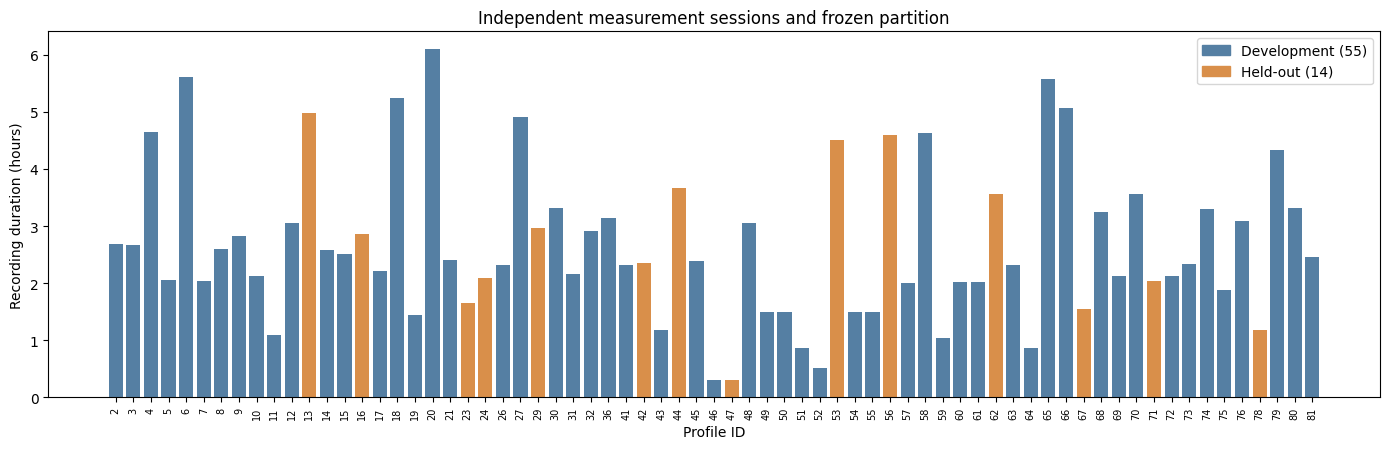

In [4]:
# 2.2.1 — Verify profile partition and visualise size distribution.
profile_summary=(raw.groupby('profile_id',sort=True).agg(observations=('pm','size'),pm_max=('pm','max')).reset_index())
profile_summary['temperature_group']=pd.qcut(profile_summary.pm_max,q=3,labels=['Low','Medium','High'])
recalc_dev,recalc_test=allocate_profiles(profile_summary, test_fraction=0.20, seed=SEED)
assert sorted(map(int,recalc_dev))==LOCKED_DEVELOPMENT_IDS
assert sorted(map(int,recalc_test))==LOCKED_TEST_IDS
assert len(set(LOCKED_DEVELOPMENT_IDS)&set(LOCKED_TEST_IDS))==0
profile_summary['partition']=np.where(profile_summary.profile_id.isin(LOCKED_TEST_IDS),'Held-out','Development')
full_dev=raw.loc[raw.profile_id.isin(LOCKED_DEVELOPMENT_IDS)].copy()
full_test=raw.loc[raw.profile_id.isin(LOCKED_TEST_IDS)].copy()
assert (len(full_dev),len(full_test))==(1_055_198,275_618)
print('PASS: 55 development profiles / 14 held-out profiles; no overlap.')
fig,ax=plt.subplots(figsize=(14,4.6))
colors=profile_summary.partition.map({'Development':'#557fa3','Held-out':'#d98f4a'})
ax.bar(profile_summary.profile_id.astype(str),profile_summary.observations/7200,color=colors)
ax.set(xlabel='Profile ID',ylabel='Recording duration (hours)',title='Independent measurement sessions and frozen partition')
ax.tick_params(axis='x',rotation=90,labelsize=7)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='#557fa3',label='Development (55)'),Patch(color='#d98f4a',label='Held-out (14)')]);fig.tight_layout()
fig.savefig(FIG_DIR/'02_profile_split.png',dpi=160,bbox_inches='tight');plt.show()
profile_summary.to_csv(RESULTS_DIR/'profile_partition.csv',index=False)
assert_locked_partition(recalc_dev, recalc_test)



## RQ1 — Profile isolation, temporal memory and permitted information

A recording profile is one laboratory session. Adjacent 0.5-second measurements share a slowly evolving thermal state. Mixing rows from one session across fitting and evaluation allows the predictor to be tested on strongly related conditions. The supplied naive 80% row cutoff puts profile 65 on both sides. Assigning entire profiles prevents this specific overlap; it does not make all sessions statistically independent or establish future chronological forecasting (Roberts et al., 2017).

The retained split applies `train_test_split` to the sorted profile table, stratified by three `qcut` bins of each profile's maximum measured `pm`, with test fraction 0.20 and seed 42. It yields 55 development profiles / 1,055,198 rows and 14 final profiles / 275,618 rows. The 55 development profiles are then split using `StratifiedKFold(n_splits=3, shuffle=True, random_state=42)` on a newly computed development-only tertile label. Validation folds contain 19/18/18 profiles and 401,114/362,087/291,997 complete observations. These assignments must not change if a dependency update changes allocation behaviour.

This allocation is *retrospective and target-informed*: the final profiles' target maxima were used to form the allocation strata. After allocation, those targets are excluded from feature construction, scaling, hyperparameter selection and model fitting. A fully blind prospective test would be a different design; it is not silently substituted here. Final MLP training has an additional row-based internal stopping set drawn only from development rows. That stopping set is temporally correlated with its fit rows, so the internal early-stopping score cannot be called profile-disjoint validation.

For one scalar input \(x_t\), span \(s\) gives \(\alpha=2/(s+1)\), \(q=1-\alpha\), and normalised finite-history weights \(w_{t,k}=q^{t-k}\). The exact retained transformations are

\[
\mu_t=\frac{\sum_{k=0}^t w_{t,k}x_k}{\sum_{k=0}^t w_{t,k}},\qquad
\sigma_t=\sqrt{\frac{\sum_{k=0}^t w_{t,k}(x_k-\mu_t)^2}{\sum_{k=0}^t w_{t,k}}}.
\]

Pandas `adjust=True` and `.std(bias=True)` implement these normalised population moments (pandas development team, 2024). Thus \(\mu_0=x_0\), \(\sigma_0=0\). Both restart at each profile boundary. Current input is allowed because this is contemporaneous temperature estimation; future inputs and previous-profile state are not. Target temperatures never enter the 108 predictors. The supplied feature tests perturb future inputs and another profile to verify that earlier features remain unchanged.

The thermal analogy is a first-order low-pass response: \(\tau\dot z+z=x\). Backward-Euler discretisation gives \(z_t=(1-\alpha)z_{t-1}+\alpha x_t\) with \(\alpha=h/(\tau+h)\). Hence \(\tau=h(1-\alpha)/\alpha=h(s-1)/2\), for \(h=0.5\) s. This motivates several memory scales; it does **not** identify an actual motor thermal resistance or heat capacity. The fixed-gain recurrence is not identical to finite-history `adjust=True` near start-up; the retained implementation and explicit weighted formula govern this project.

With twelve instantaneous predictors, four spans and two moments per predictor, the model has \(12+12\cdot4\cdot2=108\) predictors. Spans are counts, not hard rectangular windows. Features are generated from the complete original history before selecting a regression sample. The nested 80/160/320/640/1280 budgets change the number of training observations, not the 2 Hz filter timestep. Sampling the raw signal first would change the method and is prohibited.


# Chapter 3 — Physics-informed features and thermal memory

### 3.1 Twelve instantaneous predictors

Seven original measured quantities (ambient and coolant temperature, $u_d,u_q,i_d,i_q$, motor speed) are combined with five derived quantities: voltage magnitude $u_s$, current magnitude $i_s$, a proportional electrical apparent power $S_{el}=1.5u_si_s$, and two speed interactions. The target `pm` and profile ID are **excluded** from predictors.

### 3.2 Why 108 features?

For each of the 12 predictors, create an exponentially weighted mean (**EWMA**) and standard deviation (**EWMS**) for four frozen smoothing spans. Thus

\[
12 + 12\times4\times2=108\text{ features.}
\]

These calculations use only the current and earlier measurements **within the same profile** (`adjust=True`, `bias=True`), restarting at every profile boundary. The spans are in sample counts; at 2 Hz they represent different thermal history scales. A large span does not permit looking into the future.

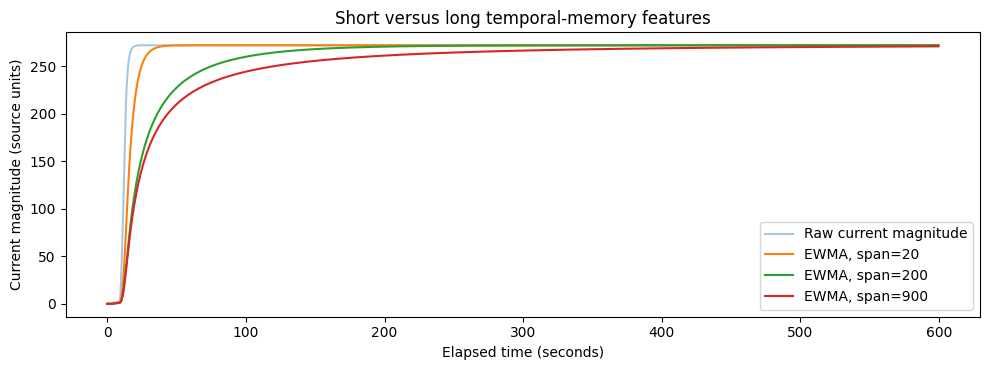

In [5]:
# 3.2.1 — One canonical feature function for training AND held-out inference.
BASE_COLS=['theta_a','theta_c','u_d','u_q','i_d','i_q','n_mech','u_s','i_s','S_el','i_s_omega','S_el_omega']
from pmsm_project.features import make_paper_inputs

from pmsm_project.features import feature_names

from pmsm_project.features import feature_frame

# Demonstrate EWMA memory using one development profile; no model is fitted.
pid=LOCKED_DEVELOPMENT_IDS[0];pr=full_dev.loc[full_dev.profile_id.eq(pid)].iloc[:1200]
base=make_paper_inputs(pr);sig=base['i_s']
fig,ax=plt.subplots(figsize=(10,3.8))
t=np.arange(len(sig))/FS_HZ
ax.plot(t,sig.to_numpy(),alpha=.4,label='Raw current magnitude')
for s in (20,200,900):ax.plot(t,sig.ewm(span=s,adjust=True).mean().to_numpy(),label=f'EWMA, span={s}')
ax.set(xlabel='Elapsed time (seconds)',ylabel='Current magnitude (source units)',title='Short versus long temporal-memory features');ax.legend();fig.tight_layout()
fig.savefig(FIG_DIR/'03_ewma_memory.png',dpi=160,bbox_inches='tight');plt.show()

# Chapter 4 — Numerical verification and validation boundaries

### 4.1 Verify the temporal transformation

Compare the canonical feature implementation with an independently constructed grouped pandas reference on a short profile. Verify first-row EWMA and EWMS analytically; ensure feature order and finiteness. **No held-out measurements are used for training or validation.**

### 4.2 Grouped three-fold validation (historical method)

The historical model-selection experiments used three grouped folds of the *55 development profiles*, stratified by peak temperature. Final settings are already frozen; we show the fold partition for provenance rather than replaying expensive Bayesian searches. This is a reconstruction of the final selected models, **not a claim to reproduce hyperparameter selection**.

PASS: 108 features and temporal moments match the independent pandas reference.


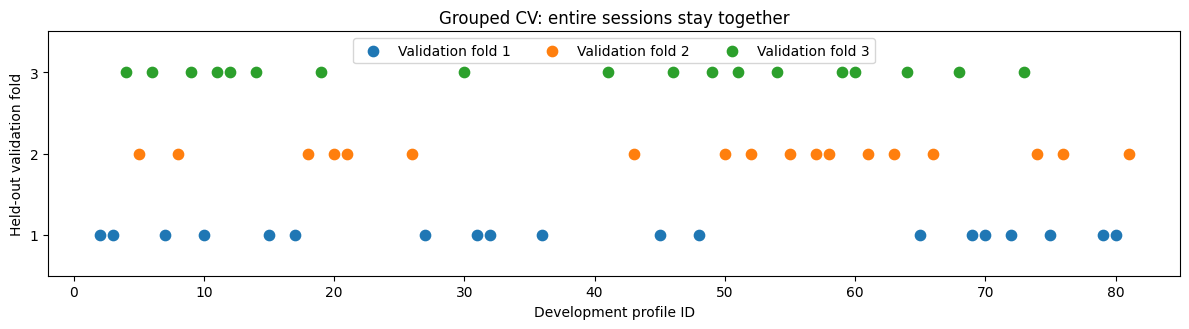

In [6]:
# 4.1.1 — Numerical feature checks, plus development-only fold schematic.
p=full_dev.loc[full_dev.profile_id.eq(LOCKED_DEVELOPMENT_IDS[0])].iloc[:30]
a=feature_frame(p,(10,50,200,1000));b=make_paper_inputs(p)
for col in BASE_COLS:
    for s in (10,50,200,1000):
        ref=b[col].ewm(span=s,adjust=True)
        np.testing.assert_allclose(a[f'{col}_ewma_s{s}'].to_numpy(),ref.mean().to_numpy(),atol=1e-12)
        np.testing.assert_allclose(a[f'{col}_ewms_s{s}'].to_numpy(),ref.std(bias=True).to_numpy(),atol=1e-12)
        assert abs(a[f'{col}_ewma_s{s}'].iloc[0]-b[col].iloc[0])<1e-9
        assert abs(a[f'{col}_ewms_s{s}'].iloc[0])<1e-9
print('PASS: 108 features and temporal moments match the independent pandas reference.')
cv=profile_summary.loc[profile_summary.partition.eq('Development'),['profile_id','pm_max','observations']].copy().reset_index(drop=True)
cv['strata']=pd.qcut(cv.pm_max,q=3,labels=['Low','Medium','High']);cv['fold']=0
skf=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
for fold,(_,val_idx) in enumerate(skf.split(cv[['pm_max']],cv.strata),start=1):cv.loc[val_idx,'fold']=fold
assert len(cv)==55 and set(cv.fold)=={1,2,3}
fig,ax=plt.subplots(figsize=(12,3.4));z=cv.sort_values('profile_id')
for k in (1,2,3):
    y=np.where(z.fold.eq(k),k,np.nan)
    ax.scatter(z.profile_id,y,s=55,label=f'Validation fold {k}')
ax.set(yticks=[1,2,3],ylim=(0.5,3.5),xlabel='Development profile ID',ylabel='Held-out validation fold',title='Grouped CV: entire sessions stay together');ax.legend(ncol=3,loc='upper center');fig.tight_layout()
fig.savefig(FIG_DIR/'04_grouped_cv.png',dpi=160,bbox_inches='tight');plt.show()
cv.to_csv(RESULTS_DIR/'development_cv_folds.csv',index=False)


## RQ2 — Baseline accuracy, optimisation and computational cost

The baseline purpose is to compare credible regression families on the same engineering target rather than infer that complexity alone improves accuracy. For feature row \(x_i\in\mathbb R^{108}\), OLS predicts \(\hat y_i=b+x_i^T\beta\). It minimises \(\sum_i(y_i-b-x_i^T\beta)^2\), uses 109 fitted unknowns including the intercept, and is inexpensive at inference. Linear coefficients remain associations between correlated thermal-memory predictors, not causal motor parameters.

Nearest-neighbour regression predicts a distance-weighted average of 54 nearby training vectors in the frozen final configuration. It retains the training observations, so a small fit time can coexist with costly inference and large persistent storage. Scaling is necessary for meaningful distances between mixed-unit predictors. Random Forest averages bootstrap-trained, feature-randomised trees; Extra Trees adds random split thresholds (Breiman, 2001; Geurts et al., 2006). Both retain this project's `max_features='sqrt'` and selected bootstrap setting. Their finite partition representation can be fast to evaluate, but does not justify extrapolation outside observed operating conditions.

The final MLP has one hidden layer of four ReLU units and a scalar linear output, trained with Adam. Backpropagation supplies the gradient through the differentiable network (Rumelhart et al., 1986; Kingma and Ba, 2015). It can represent nonlinear relationships using far fewer retained observations than k-NN, but is stochastic and sensitive to conditioning and stopping. The supplied development factory (`max_iter=200`, no early stopping), Stage 3 smoke MLP (`max_iter=150`), and final MLP (`max_iter=400`, 10% row-based early stopping, patience 15) are distinct experiments. Their settings are retained and their results must not be treated as identical optimisation protocols.

### The executable Bayesian investigation and the missing provenance

The supplied executable search is an **eight-evaluation OLS pilot** over integer spans \([5,30],[31,150],[151,700],[701,3000]\). `gp_minimize` uses four initial random points, expected improvement (`acq_func='EI'`) and seed 42. Each candidate rebuilds full-history features, selects the same 80 evenly spaced observations per development profile (4,400 rows), fits train-only input scaling and OLS in each of three fixed grouped folds, and returns their *unweighted mean MSE*. The objective is in °C². No target scaler is used for this OLS pilot. The Gaussian-process surrogate balances exploring uncertain candidates with exploiting likely improvements (Snoek et al., 2012; scikit-optimize developers, 2024). Neither a Gaussian-process surrogate nor a finite trial budget guarantees a global optimum.

The uploaded saved pilot's best spans are (30,150,652,3000), mean CV MSE 45.64670386344714 °C², compared with 64.639936 °C² for spans (10,50,200,1000). These are historical source outputs; a new execution is reported separately. A boundary winner suggests restricted search coverage, not a mathematical proof that larger bounds will improve generalisation. The supplied code also defines an expanded cumulative-gap encoding with bounds [5,100], [1,400], [1,1500], [1,6000] and model-specific search spaces. Encoding verification and defining an objective do not constitute executing a search.

**Critical limit:** Stages 1–8 explicitly state that the historical long Bayesian searches, 12-trial five-model searches and later refinement were omitted from this upload. Their complete trial traces, objective implementations at their original budgets and acquisition settings are not recoverable from the provided files. The final five baseline configurations are therefore retained as *historical frozen inputs*, not outputs of the eight-trial OLS pilot. In particular final OLS spans (67,97,693,3339) cannot be obtained from that pilot's bounds. The exact historical RQ2 optimisation-to-selection chain remains incomplete. No synthetic reconstruction or substitute search is supplied under the original experiment's name.

### Interpreting costs

OLS's final `fit_seconds` includes feature construction, profile QR, moment aggregation and the solve. Other final model fit timers start after their feature matrices are built. Stage 9 screening timers exclude already completed standardisation; Nyström fit/predict timers include their mapping. The final inference timer begins **after joblib loading**, and includes the model-file checksum, feature construction, prediction and checkpoint I/O. The source Markdown's claim that it includes deserialisation is inaccurate. These are retained timer boundaries; compare them with this caveat instead of claiming a hardware-independent speedup. Runtime repetitions in Stage 5 equal one; between-fold variation is not repeat timing uncertainty.


# Chapter 5 — Frozen selected models and computational hypotheses

### 5.1 Precommitted model configurations

Hyperparameters and temporal spans below originate from earlier **development-only** experiments. They are specified before the final test evaluation. All non-OLS models fit a `StandardScaler` for predictors and an independent `StandardScaler` for the target, using **only development observations**.

The five originally benchmarked models use their original families and selected parameters. The sixth is `LinearSVR` with a sample-size-scaled regularisation heuristic, chosen to avoid a computationally infeasible full-data exact RBF-SVR. The full-data RBF-SVR is **not** presented as a successfully fitted final model.

### 5.2 Interpreting the question

A larger model can have lower test error without being computationally feasible. Training cost, inference cost, worst-profile error and signed bias are distinct deployment considerations. Historical research observed full-data k-NN inference to be substantially slower than the other estimators.

In [7]:
# 5.1.1 — Frozen settings. This manifest is written before final test predictions.
from pmsm_project.config import frozen_configurations, TRAIN_ORDER, REPORT_ORDER
FROZEN = frozen_configurations()
assert set(TRAIN_ORDER)==set(FROZEN) and all(len(v['spans'])==4 for v in FROZEN.values())
assert len(LOCKED_DEVELOPMENT_IDS)==55 and len(LOCKED_TEST_IDS)==14
frozen_manifest={'source_sha256':EXPECTED_SHA256,'random_state':SEED,
  'development_profile_ids':LOCKED_DEVELOPMENT_IDS,'test_profile_ids':LOCKED_TEST_IDS,
  'feature_engineering':'EWMA_EWMS_v1_adjust_true_bias_true',
  'base_feature_order':BASE_COLS,'models':FROZEN,'original_model_selection':'frozen from prior development-only research'}
(RESULTS_DIR/'frozen_experiment.json').write_text(json.dumps(frozen_manifest,indent=2))
print('Frozen settings written before final evaluation. Final test scores are not used for selection.')

Frozen settings written before final evaluation. Final test scores are not used for selection.



## RQ4 — Numerical credibility, convergence and limits of evidence

A 108-column float64 full-development matrix alone occupies 911,691,072 bytes (about 0.849 GiB); scalers, model structures, solver copies, raw data and QR workspaces require additional memory. A conceptual dense N-by-N float64 kernel at N=1,055,198 would need about 8.91 TB. LIBSVM uses a bounded kernel cache rather than necessarily allocating that dense matrix; this estimate explains scaling pressure, not observed allocation or a universal exact runtime law.

For OLS, set \(A_j=[\mathbf1,X_j,y_j]\) for profile j and factor \(A_j=Q_jR_j\). Orthogonality gives \(\|A_jv\|_2^2=\|R_jv\|_2^2\) for any compatible v. Summing over profiles preserves the total least-squares objective when their R factors are stacked. Profile moments are combined by

\[
\mu=\frac{\sum_jn_j\mu_j}{N},\qquad
v=\frac{\sum_jn_j[v_j+(\mu_j-\mu)^2]}{N}.
\]

The between-profile term is essential: averaging variances alone loses shifts in means. For a compressed augmented factor, standardisation is effected by \(R_X^{scaled}=(R_X-R_1\mu^T)/d\), with population scales \(d_k=\sqrt{v_k}\) and zero scales replaced by one. `lstsq(..., lapack_driver='gelsd')` solves the transformed system; raw-space coefficients are recovered as \(\beta_k=w_k/d_k\), \(b=w_0-\mu^T\beta\). These are the original numerical operations (SciPy developers, 2025). They avoid explicitly forming \((X^TX)^{-1}\), which can amplify conditioning problems.

Verification checks direct versus compressed residual norms on real profile data, independently computed weighted moments, full-history versus sampled features, train-only moment aggregation, QR versus scikit-learn predictions on the same 4,400-row sample, and train-save-reload-predict invariance. Historical QR/sklearn maximum prediction difference is about 1.471e-12 °C. Tolerances assess floating-point agreement (not physical sensor accuracy). Test fixtures use rtol 1e-11 for a residual identity; the original real-data experiments retain their own tolerances. Nearly collinear synthetic features are assessed by predictions rather than unstable individual coefficient values. The full OLS code retains its rank-109 assertion and does not silently change rank thresholds.

Stage 3's historical OLS estimate of 239.77 °C for profile 65 at its initial sample is retained. Its largest error contributes about 33.9% of that sample's SSE. Removing it only for an explicitly labelled influence diagnostic is not an improved model result; all fitting and official metrics retain the point. Plausible insufficient initial-state information is an interpretation, not a proven physical cause. No clipping, replacement, burn-in deletion or alternative estimator is introduced.

A `ConvergenceWarning` is retained as numerical evidence. No warning means the solver's configured stopping test was met, not proof of globally optimal engineering performance. Full final training aborts on a convergence warning as the source requires; it does not silently increase `max_iter` or change a solver. Stage 9 records unsuccessful/nonconverged candidates and excludes warned candidates from the specified selection steps.

Fold SD reflects changes in validation sessions and overlapping training sets. Three folds are not independent repetitions and do not support a claimed 95% confidence interval. Stage 9H nests C selection only: its spans and epsilon were fixed from prior development work, so it is not fully nested assessment of the entire feature/hyperparameter search. Stage 9I selects and reports on the same development folds and therefore supports selection, not an unbiased final generalisation estimate. Repeated manual inspection of Fold 1 can also make its screening estimates optimistic.

Historical timing and RSS are hardware/process-specific. RSS polling at 0.05 or 0.1 seconds can miss brief peaks, includes interpreter/kernel and retained arrays, and is not isolated estimator allocation. A single timing is descriptive. These qualifications preserve the unsuccessful experiments and provide engineering limits to positive findings.


# Chapter 6 — Profile-wise QR-compressed ordinary least squares

### 6.1 Why use QR compression?

OLS solves a least-squares problem in $109$ unknowns (108 predictors plus intercept), but the development dataset has more than one million rows. Rather than building and solving a giant dense design matrix in one operation, QR compression reduces blocks of observations to equivalent triangular factors. If $A=QR$ with orthonormal $Q$, then $\|A\beta-y\|_2^2$ is preserved through the augmented QR representation.

We reproduce the original project's numerical method, including pooled development-only feature scaling and rank verification. OLS training is distinguished from the later neural/tree/SVR estimators.

In [8]:
# 6.1.1 — Reproduced original profile-wise QR method.
from pmsm_project.numerics import qr_compress_profile

from pmsm_project.numerics import fit_qr_ols

# Independent synthetic-data check: augmented QR and ordinary lstsq agree.
rng=np.random.default_rng(SEED)
xx=rng.normal(size=(400,8));yy=xx@rng.normal(size=8)+rng.normal(scale=.01,size=400)
A=np.column_stack((np.ones(len(xx)),xx));R=qr(np.column_stack((A,yy)),mode='r')[0]
a=lstsq(R[:,:-1],R[:,-1])[0];b=lstsq(A,yy)[0]
np.testing.assert_allclose(a,b,rtol=1e-8,atol=1e-8)
print('PASS: QR-compressed least squares matches a direct independent solver.')

PASS: QR-compressed least squares matches a direct independent solver.


# Chapter 7 — Full-development fitting protocol

### 7.1 Hold the protocol constant

All estimators train on the 55 development profiles. Different smoothing spans are fixed per model. **Each model builds its own 108-feature matrix**, which prevents mismatched temporal features. To control memory usage, train and save *one estimator at a time*, then release its feature matrix. Saved local artifacts are an output of the notebook, **never a prerequisite**.

For real final results, the expected training counts are 1,055,198 observations and 55 independent sessions for all six models. A smoke run uses a small prefix of each profile and is deliberately isolated under `smoke/`.

### 7.2 Common pipeline definitions

Historical tree models used `max_features='sqrt'`, `n_jobs=2`, seed 42; MLP used one four-unit hidden layer, Adam, mini-batches of 64 and early stopping. These details must be preserved to avoid an undocumented methodological change.

**Resource pre-flight.** The full-data fitted artifacts can consume several gigabytes, particularly the k-NN, Random Forest and Extra Trees models. Allow adequate memory and disk space in Colab. Because the notebook intentionally builds models locally without mandatory Drive storage, Colab runtime termination can erase progress; downloading the output ZIP or selecting an explicitly mounted persistent output directory is an optional archival step, not a model dependency.


In [9]:
# 7.2.1 — Single model factory and profile-wise training matrix.
from pmsm_project.models import build_pipeline

def relevant_profiles(df,is_test=False):
    groups=df.groupby('profile_id',sort=False)
    if RUN_MODE=='full': return [(int(pid),block) for pid,block in groups]
    # Only a small early-time prefix of each session: workflow verification, not science.
    return [(int(pid),block.iloc[:120 if not is_test else 160]) for pid,block in groups]

def build_training_matrix(data,spans):
    blocks=relevant_profiles(data)
    n=sum(len(p) for _,p in blocks);names=feature_names(spans)
    X=np.empty((n,108),dtype=np.float64);y=np.empty(n,dtype=np.float64)
    cursor=0
    for pid,profile in blocks:
        features=feature_frame(profile,spans)
        nxt=cursor+len(profile)
        X[cursor:nxt]=features[names].to_numpy(dtype=np.float64)
        y[cursor:nxt]=profile.pm.to_numpy(dtype=np.float64)
        cursor=nxt
    assert cursor==n and np.isfinite(X).all() and np.isfinite(y).all()
    return X,y,names,len(blocks)

# IMPORTANT: this is an explicit test of the model construction, not a model fit.
for name in [s for s in TRAIN_ORDER if s!='OLS']:
    p=build_pipeline(name); assert hasattr(p,'fit')
print('PASS: Model pipeline factory and all six frozen configurations ready.')

PASS: Model pipeline factory and all six frozen configurations ready.


# Chapter 8 — Full-development estimator construction

The following subsections deliberately use **numerical chapter identifiers** (8.1.1, 8.1.2, ...) rather than the exploratory notebook's lettered stages. Every section uses the same train → verify → persist sequence. Running the notebook from a fresh runtime creates the models locally.

### 8.1.1 — Fit the six frozen estimators

OLS is solved using the QR method from Chapter 6. k-NN, Extra Trees, MLP, Random Forest and LinearSVR use the original training-only scaled estimators. `joblib` artifacts and JSON records are produced by this notebook, with feature names and checksums for provenance. Training and inference timings are measured anew; historical timings are not substituted.

When `RUN_MODE='smoke'`, reduced samples are used; all summaries and checkpoints are marked **SMOKE**. Never combine them with published held-out results.

In [10]:
# 8.1.1 — Genuine final training: no historical model downloads or Drive mount.
TRAIN_RESULTS=[]
for name in TRAIN_ORDER:
    print('\n'+'='*60+'\nTRAINING:',name,'\n'+'='*60,flush=True)
    spans=FROZEN[name]['spans'];path=MODELS_DIR/(name.replace(' ','_').replace('-','')+'.joblib')
    # Explicitly computed each run; no conditional restoration from other sessions.
    if name=='OLS':
        # SMOKE uses the same QR algorithm with only initial data from each development profile.
        data=full_dev if RUN_MODE=='full' else pd.concat([p for _,p in relevant_profiles(full_dev)])
        bundle=fit_qr_ols(data,spans)
        n_rows=bundle['train_rows'];n_profiles=data.profile_id.nunique()
        fit_s=bundle['fit_seconds'];warnings_n=0
        if RUN_MODE=='full': assert bundle['rank']==109
    else:
        X,y,names,n_profiles=build_training_matrix(full_dev,spans)
        n_rows=len(y)
        pipe=build_pipeline(name)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always',ConvergenceWarning)
            start=time.perf_counter();pipe.fit(X,y);fit_s=time.perf_counter()-start
        warnings_n=sum(issubclass(w.category,ConvergenceWarning) for w in caught)
        if warnings_n:
            raise RuntimeError(f'{name} issued {warnings_n} convergence warnings; investigate, do not silently certify.')
        bundle={'model':name,'type':'sklearn','pipeline':pipe,'spans':spans,
                'feature_names':names,'train_rows':n_rows,'fit_seconds':fit_s}
        # Verify development-only prediction and persistence without touching test profiles.
        sample_X=X[:min(32,len(X))].copy();dev_pred=pipe.predict(sample_X)
        assert np.isfinite(dev_pred).all()
        del X,y,pipe;gc.collect()
    if RUN_MODE=='full': assert n_rows==1_055_198 and n_profiles==55
    else: assert n_rows==120*55 and n_profiles==55
    joblib.dump(bundle,path,compress=1)
    del bundle  # Avoid loading a duplicate million-row k-NN/forest estimator in RAM.
    gc.collect()
    if name!='OLS':
        restored=joblib.load(path)
        np.testing.assert_allclose(restored['pipeline'].predict(sample_X),dev_pred,atol=1e-8,rtol=1e-8)
        del restored,sample_X,dev_pred
    row={'Model':name,'Train_Rows':int(n_rows),'Train_Profiles':int(n_profiles),
         'Fit_s':float(fit_s),'Convergence_Warnings':int(warnings_n),
         'Model_File':str(path),'Artifact_SHA256':sha256_file(path),'Mode':RUN_MODE}
    TRAIN_RESULTS.append(row)
    (RESULTS_DIR/'training_manifest.json').write_text(json.dumps(TRAIN_RESULTS,indent=2))
    print('PASS:',name,'|',f'{n_rows:,}','training observations |',round(fit_s,2),'s')
    gc.collect()
train_metrics=pd.DataFrame(TRAIN_RESULTS).set_index('Model').loc[REPORT_ORDER].reset_index()
assert len(train_metrics)==6 and train_metrics.Convergence_Warnings.sum()==0
train_metrics.to_csv(RESULTS_DIR/'training_times.csv',index=False)
print('\nPASS: Six estimators fitted from the raw data in this runtime.')


TRAINING: OLS 
PASS: OLS | 1,055,198 training observations | 8.11 s

TRAINING: k-NN 
PASS: k-NN | 1,055,198 training observations | 0.89 s

TRAINING: Extra Trees 
PASS: Extra Trees | 1,055,198 training observations | 83.49 s

TRAINING: MLP 
PASS: MLP | 1,055,198 training observations | 47.21 s

TRAINING: Random Forest 
PASS: Random Forest | 1,055,198 training observations | 738.37 s

TRAINING: LinearSVR 
PASS: LinearSVR | 1,055,198 training observations | 21.96 s

PASS: Six estimators fitted from the raw data in this runtime.


### 8.1.2 — Training efficiency and artifact checks

A fast *fit* is not necessarily a fast predictor: k-NN retains its million-row neighbour data and searches it at inference. Random Forest fitting can be costly even if prediction is comparatively quick. Figure 8.1 measures the newly generated fit times, not copied historical values.

Training artifacts checksum-verified: 6


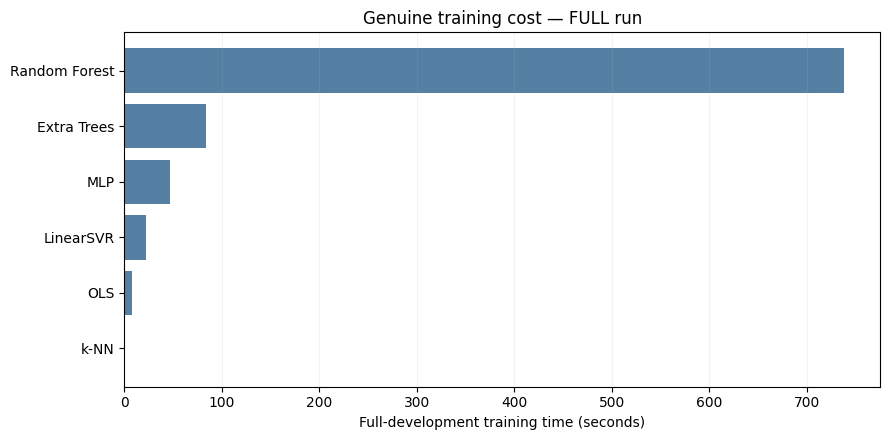

In [11]:
# 8.1.2 — Fit time chart from the current clean execution.
fig,ax=plt.subplots(figsize=(9,4.5))
d=train_metrics.sort_values('Fit_s',ascending=True)
ax.barh(d.Model,d.Fit_s,color='#557fa3')
ax.set(xlabel='Full-development training time (seconds)' if RUN_MODE=='full' else 'Smoke training time (seconds)',
       title=f'Genuine training cost — {RUN_MODE.upper()} run')
ax.grid(axis='x',alpha=.15)
fig.tight_layout();fig.savefig(FIG_DIR/'08_training_times.png',dpi=160,bbox_inches='tight');plt.show()
print('Training artifacts checksum-verified:',len(train_metrics))

# Chapter 9 — Held-out inference without private artifacts

### 9.1 Evaluation is performed only after training is complete

Restore one newly generated local model at a time. For every original held-out profile, generate the **same model-specific features** from that profile's own chronological history, compute predictions in bounded batches, then save a row-aligned `.npz` checkpoint. This makes slow k-NN inference restartable when an output folder is kept between runs. A fresh run still needs **no historical models**.

In `full` mode, evaluate all 14 original test profiles and all 275,618 target values. In `smoke` mode, use 14 short profile prefixes solely to check mechanics. The actual timer starts after deserialisation and includes model-file checksum/feature preparation/checkpoints and is **not** pure estimator prediction latency.
**Execution behaviour:** inference checkpoints are written after each model/profile, but the retained cell overwrites them on rerun. There is no automatic resume/skip logic. They support audit and manual recovery, not a promise of automatic restart from a partial cell.


In [12]:
# 9.1.1 — Reproducible 84 model-profile inference checkpoints.
INFERENCE_TIMES=[]
for name in TRAIN_ORDER:
    path=MODELS_DIR/(name.replace(' ','_').replace('-','')+'.joblib')
    assert path.is_file()
    bundle=joblib.load(path)
    assert bundle['train_rows']==(1_055_198 if RUN_MODE=='full' else 6_600)
    spans=bundle['spans'];expected_names=feature_names(spans)
    assert bundle['feature_names']==expected_names
    model_start=time.perf_counter();count=0
    model_sha=sha256_file(path)
    target_dir=PRED_DIR/(name.replace(' ','_').replace('-',''))
    target_dir.mkdir(parents=True,exist_ok=True)
    for pid,profile in relevant_profiles(full_test,is_test=True):
        dest=target_dir/f'profile_{pid:03d}.npz'
        rows=profile.index.to_numpy(dtype=np.int64)
        Xtest=feature_frame(profile,spans)[expected_names].to_numpy(dtype=np.float64)
        prediction=np.empty(len(Xtest),dtype=np.float64)
        chunk=64 if name=='k-NN' else 4096
        for k in range(0,len(Xtest),chunk):
            xi=Xtest[k:k+chunk]
            if name=='OLS': prediction[k:k+chunk]=bundle['intercept']+xi@bundle['coef']
            else: prediction[k:k+chunk]=bundle['pipeline'].predict(xi)
        assert np.isfinite(prediction).all() and len(prediction)==len(rows)
        np.savez_compressed(dest,model=name,profile_id=int(pid),source_row=rows,prediction=prediction,
            mode=RUN_MODE,artifact_sha256=model_sha)
        count+=1
        del Xtest,prediction
    assert count==14
    elapsed=time.perf_counter()-model_start
    INFERENCE_TIMES.append({'Model':name,'Inference_Loop_s':elapsed,'Profiles':count,'Mode':RUN_MODE})
    print('PASS:',name,'|',count,'original test profiles |',round(elapsed,2),'s')
    del bundle;gc.collect()
inference_metrics=pd.DataFrame(INFERENCE_TIMES)
inference_metrics.to_csv(RESULTS_DIR/'inference_times.csv',index=False)
assert len(list(PRED_DIR.glob('*/*.npz')))==84
print('PASS: 84 saved prediction files; test observations never entered model fitting.')

PASS: OLS | 14 original test profiles | 0.79 s
PASS: k-NN | 14 original test profiles | 1581.73 s
PASS: Extra Trees | 14 original test profiles | 3.99 s
PASS: MLP | 14 original test profiles | 1.02 s
PASS: Random Forest | 14 original test profiles | 3.62 s
PASS: LinearSVR | 14 original test profiles | 0.96 s
PASS: 84 saved prediction files; test observations never entered model fitting.



## Frozen final evaluation and interpretation

Notebook 2 has no Bayesian optimisation. Its six model-specific span/configuration records are written before test predictions. Every full model is fitted on all 55 development profiles. The test set remains the same 14 complete sessions; EWM features use each session's own current/past observable inputs, not its target or another session's history. The code saves 84 model/profile prediction arrays with original row indices, then reconstructs metrics from measured targets. It trains locally and does not load another person's saved model.

For \(e_i=\hat y_i-y_i\), \(\mathrm{MSE}=N^{-1}\sum e_i^2\), \(\mathrm{RMSE}=\sqrt{\mathrm{MSE}}\), \(\mathrm{MAE}=N^{-1}\sum|e_i|\), \(\mathrm{Bias}=N^{-1}\sum e_i\), and \(R^2=1-\sum e_i^2/\sum(y_i-\bar y)^2\). Constant-target R² is NaN in the supplied final implementation. P95 and maximum absolute error quantify the tail of the *observed* error, not a guaranteed bound. Pooled metrics weight rows equally and longer sessions more heavily; macro RMSE averages profile RMSEs equally. Worst-profile RMSE and signed bias reveal session differences that pooled values hide.

The identity \(\mathrm{MSE}=\mathrm{Bias}^2+\operatorname{Var}(e)\) uses population error variance. The error heatmap, largest absolute profile biases and temperature histories are diagnostics only. The longest held-out profile is chosen by observation count before comparing histories. Neither bias fractions nor curves identify a causal thermal mechanism. Test results are never fed back into hyperparameter selection in this revision.

The provided final notebook contains **no executed code-cell outputs**. Its reference RMSE numbers (MLP 4.3627, LinearSVR 5.6653, RF 5.7651, OLS 5.9672, Extra Trees 6.1654, k-NN 9.0770 °C) are embedded historical comparison constants, not attached final prediction evidence. They are recorded with that weaker provenance. New full runs are calculated independently and compared without tuning to make them agree. Smoke-prefix scores use 6,600 training rows and 2,240 evaluation rows and cannot be compared scientifically with full-run RMSE.

Generalisation here means unseen laboratory sessions from this public motor dataset. It does not establish cross-motor transfer, field reliability, response to missing sensors, extrapolation, quantified sensor uncertainty, closed-loop stability, limit-crossing detection or real-time embedded operation. Those remain engineering limitations rather than unsupported claims.


# Chapter 10 — Final held-out accuracy and efficiency

### 10.1 Metrics computed from original measurements

We compute, for each model and profile, residual $e_i=\hat T_i-T_i$, MSE, RMSE, MAE, $R^2$, signed bias, 95th percentile absolute error and maximum absolute error. Pooled RMSE weights longer profiles more heavily; mean-profile RMSE weights each recording equally. Neither measure alone establishes safety near a temperature limit.

\[
\mathrm{RMSE}=\sqrt{\frac1N\sum_i e_i^2},\quad
\mathrm{MAE}=\frac1N\sum_i|e_i|,\quad
\mathrm{Bias}=\frac1N\sum_i e_i.
\]

**Reference (historical complete run):** MLP RMSE ≈ 4.36°C, LinearSVR ≈ 5.67°C, RF ≈ 5.77°C, OLS ≈ 5.97°C, Extra Trees ≈ 6.17°C, k-NN ≈ 9.08°C. These are comparison references, **not** injected predictions or replaced evaluation metrics. Software/hardware variation must be reported if new scores differ.

In [13]:
# 10.1.1 — Derive 84 profile metrics and six pooled metrics from saved predictions.
from pmsm_project.metrics import score
profile_rows=[];pooled_rows=[]
profile_lookup={pid:p for pid,p in relevant_profiles(full_test,is_test=True)}
for name in TRAIN_ORDER:
    yy=[];yp=[];summaries=[]
    model_dir=PRED_DIR/(name.replace(' ','_').replace('-',''))
    for pid,profile in profile_lookup.items():
        path=model_dir/f'profile_{pid:03d}.npz'
        with np.load(path,allow_pickle=False) as archive:
            assert archive['model'].item()==name and archive['mode'].item()==RUN_MODE
            np.testing.assert_array_equal(archive['source_row'],profile.index.to_numpy(dtype=np.int64))
            pred=archive['prediction'].copy()
        actual=profile.pm.to_numpy(dtype=np.float64)
        met=score(actual,pred)
        profile_rows.append({'Model':name,'Profile_ID':pid,'Observations':len(actual),**met})
        summaries.append(met);yy.append(actual);yp.append(pred)
    combined=score(np.concatenate(yy),np.concatenate(yp))
    pooled_rows.append({'Model':name,'Observations':sum(len(y) for y in yy),**combined,
       'Macro_RMSE_C':float(np.mean([m['RMSE_C'] for m in summaries])),
       'Worst_Profile_RMSE_C':float(max(m['RMSE_C'] for m in summaries))})
profile_metrics=pd.DataFrame(profile_rows)
overall_metrics=pd.DataFrame(pooled_rows).sort_values('RMSE_C').reset_index(drop=True)
assert len(profile_metrics)==84 and len(overall_metrics)==6
assert overall_metrics.Observations.eq(275_618 if RUN_MODE=='full' else 14*160).all()
profile_metrics.to_csv(RESULTS_DIR/'profile_metrics.csv',index=False)
overall_metrics.to_csv(RESULTS_DIR/'overall_metrics.csv',index=False)
print('Final held-out results' if RUN_MODE=='full' else 'SMOKE-ONLY scores (NOT research findings)')
display(overall_metrics[['Model','RMSE_C','MAE_C','R2','Bias_C','Worst_Profile_RMSE_C']].round(4))

Final held-out results


,Model,RMSE_C,MAE_C,R2,Bias_C,Worst_Profile_RMSE_C
0,MLP,4.3627,3.2879,0.9547,-0.4890,6.6995
1,LinearSVR,5.6653,3.6893,0.9236,0.4580,11.1839
2,Random Forest,5.7651,4.5125,0.9209,-1.4511,9.4252
3,OLS,5.9672,4.5709,0.9152,0.0474,8.8412
4,Extra Trees,6.1654,4.6565,0.9095,-1.5042,10.1649
5,k-NN,9.0770,6.4580,0.8039,-1.2630,14.6047


### 10.2 Visual comparison and computational trade-off

Smaller RMSE indicates smaller squared prediction error on average. The scatter figure adds computational cost: a model can be quick to train but slow to use. Report both axes explicitly; the measured inference-loop time contains feature preparation and I/O, and was not standardised as an isolated microbenchmark.

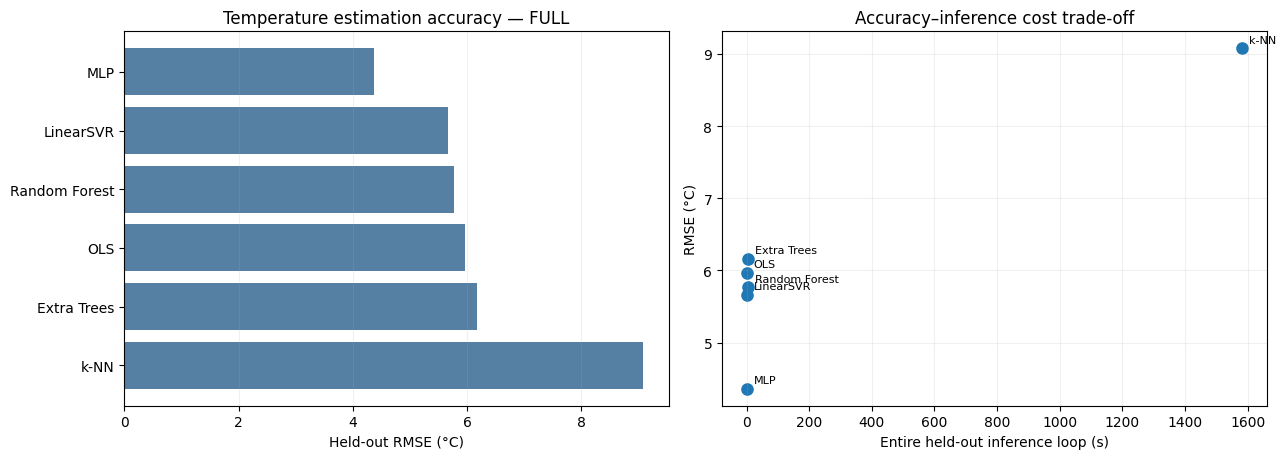

In [14]:
# 10.2.1 — Accuracy bars and prediction-cost scatter using newly recomputed metrics.
merged=overall_metrics.merge(inference_metrics,on='Model').merge(train_metrics[['Model','Fit_s']],on='Model')
fig,axes=plt.subplots(1,2,figsize=(13,4.7))
d=merged.sort_values('RMSE_C',ascending=False)
axes[0].barh(d.Model,d.RMSE_C,color='#557fa3')
axes[0].set(xlabel='Held-out RMSE (°C)',title=f'Temperature estimation accuracy — {RUN_MODE.upper()}')
axes[0].grid(axis='x',alpha=.18)
axes[1].scatter(merged.Inference_Loop_s,merged.RMSE_C,s=65)
for r in merged.itertuples():axes[1].annotate(r.Model,(r.Inference_Loop_s,r.RMSE_C),xytext=(5,4),textcoords='offset points',fontsize=8)
axes[1].set(xlabel='Entire held-out inference loop (s)',ylabel='RMSE (°C)',title='Accuracy–inference cost trade-off')
axes[1].grid(alpha=.18);fig.tight_layout()
fig.savefig(FIG_DIR/'10_accuracy_and_cost.png',dpi=160,bbox_inches='tight');plt.show()

# Chapter 11 — Generalisation across unseen recording sessions

### 11.1 What does a profile RMSE heatmap show?

Rows are recording sessions; columns are models. It answers *which model profiles are difficult*, not *which physical conditions caused them*. Pooled and worst-profile scores measure different aspects of generalisation. Previously unseen sessions are not automatically out-of-distribution or intentionally adverse.

### 11.2 Signed bias and systematic offsets

A negative signed mean error indicates average underprediction; positive indicates average overprediction. Near-zero pooled bias does **not** guarantee small individual errors. For a session, $\mathrm{MSE}=\mathrm{Bias}^2+\operatorname{Var}(e)$, so the squared mean bias and residual variance have distinct contributions. These describe error structure, not its physical cause.

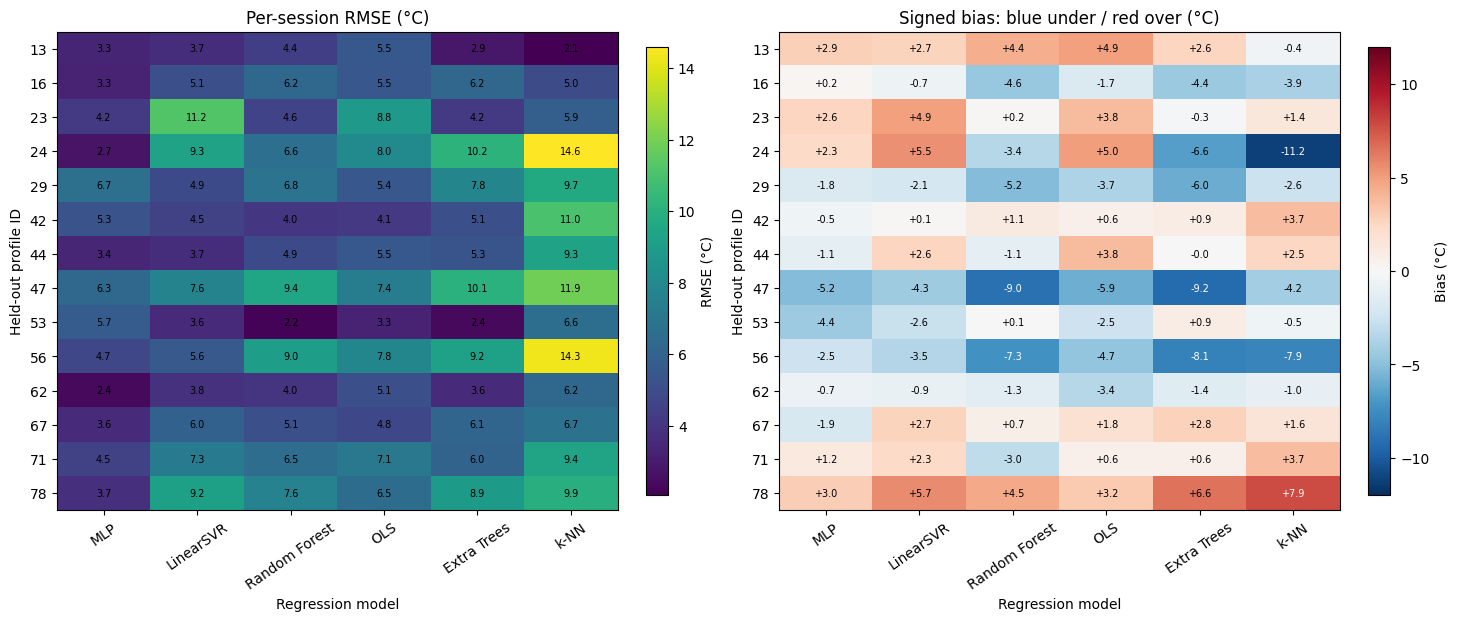

In [15]:
# 11.2.1 — Paired RMSE and signed-bias heatmaps, 14 recordings × 6 models.
from matplotlib.colors import TwoSlopeNorm
mx=profile_metrics.pivot(index='Profile_ID',columns='Model',values='RMSE_C').loc[:,REPORT_ORDER].sort_index()
bx=profile_metrics.pivot(index='Profile_ID',columns='Model',values='Bias_C').loc[:,REPORT_ORDER].sort_index()
fig,axs=plt.subplots(1,2,figsize=(14.5,6.1),constrained_layout=True)
a=axs[0].imshow(mx.to_numpy(),cmap='viridis',aspect='auto')
cap=max(1,float(np.ceil(np.max(np.abs(bx.to_numpy())))))
b=axs[1].imshow(bx.to_numpy(),cmap='RdBu_r',norm=TwoSlopeNorm(vmin=-cap,vcenter=0,vmax=cap),aspect='auto')
for ax,z,title in [(axs[0],mx,'Per-session RMSE (°C)'),(axs[1],bx,'Signed bias: blue under / red over (°C)')]:
    ax.set(xticks=range(6),xticklabels=REPORT_ORDER,yticks=range(14),yticklabels=mx.index,
           xlabel='Regression model',ylabel='Held-out profile ID',title=title)
    ax.tick_params(axis='x',rotation=35)
    for i in range(z.shape[0]):
        for j in range(z.shape[1]):
            val=z.iat[i,j]
            ax.text(j,i,f'{val:+.1f}' if ax is axs[1] else f'{val:.1f}',ha='center',va='center',fontsize=7,
                    color='white' if (ax is axs[1] and abs(val)>cap*.55) else 'black')
fig.colorbar(a,ax=axs[0],fraction=.04,label='RMSE (°C)')
fig.colorbar(b,ax=axs[1],fraction=.04,label='Bias (°C)')
fig.savefig(FIG_DIR/'11_profile_rmse_bias_heatmaps.png',dpi=170,bbox_inches='tight');plt.show()

### 11.3 What fraction of profile error is a systematic offset?

For profile $j$, `bias_contribution = 100 × bias² / RMSE²`. A high proportion indicates that the profile's **squared average signed offset** explains much of the MSE, whereas the remainder is the variance of the errors around their mean. This decomposition does not establish whether differences in operating conditions, initial motor temperature or cooling caused the error. We do **not** adjust any estimator based on these diagnostics.

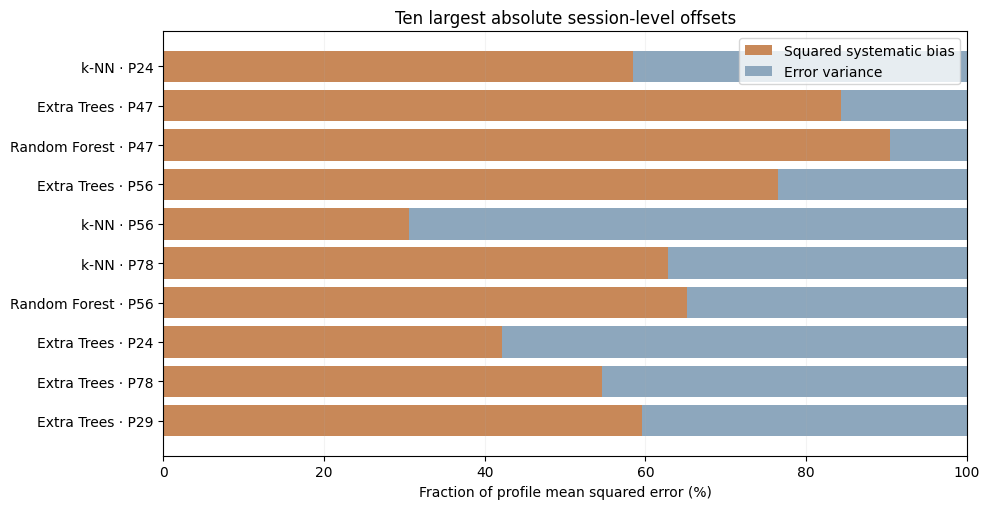

In [16]:
# 11.3.1 — Visual bias decomposition and high-bias examples.
diag=profile_metrics.copy()
diag['Absolute_Bias_C']=diag.Bias_C.abs()
diag['Bias_Contribution_Pct']=np.where(diag.RMSE_C>0,100*diag.Bias_C**2/diag.RMSE_C**2,0.0)
diag['Error_Variance_C2']=np.maximum(diag.RMSE_C**2-diag.Bias_C**2,0.)
assert diag.Bias_Contribution_Pct.between(0,100+1e-6).all()
worst=diag.nlargest(10,'Absolute_Bias_C').iloc[::-1].copy()
worst['Label']=worst.Model+' · P'+worst.Profile_ID.astype(str)
fig,ax=plt.subplots(figsize=(10,5.2))
ax.barh(worst.Label,worst.Bias_Contribution_Pct,color='#c88858',label='Squared systematic bias')
ax.barh(worst.Label,100-worst.Bias_Contribution_Pct,left=worst.Bias_Contribution_Pct,color='#8da7bd',label='Error variance')
ax.set(xlim=(0,100),xlabel='Fraction of profile mean squared error (%)',title='Ten largest absolute session-level offsets');ax.legend();ax.grid(axis='x',alpha=.15)
fig.tight_layout();fig.savefig(FIG_DIR/'11_bias_decomposition.png',dpi=160,bbox_inches='tight');plt.show()
diag.to_csv(RESULTS_DIR/'profile_bias_diagnostics.csv',index=False)

### 11.4 Link regression performance back to the physical temperature history

Use the **longest held-out recording chosen by observation count** (not by model score). The plot aligns measured magnet temperature against MLP, LinearSVR and Random Forest predictions. The time coordinate is reconstructed at 2 Hz; it is elapsed recording time, not wall-clock time. This is a diagnostic of shape/lag/offset, not proof of a particular thermal mechanism.

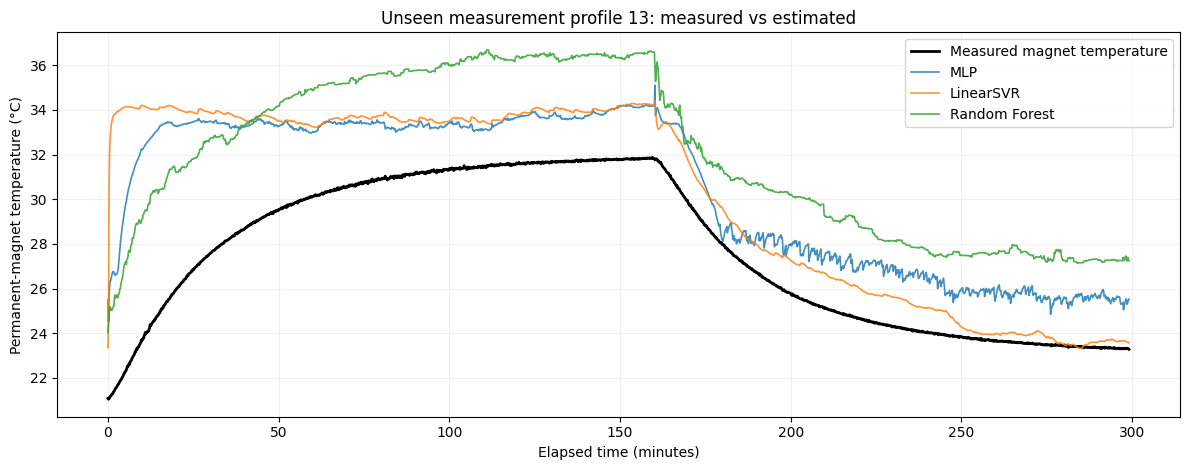

In [17]:
# 11.4.1 — Temperature history on the longest untouched session.
pid=max(profile_lookup,key=lambda j:len(profile_lookup[j]));pr=profile_lookup[pid]
time_min=np.arange(len(pr))/(FS_HZ*60)
step=max(1,len(pr)//1800)
fig,ax=plt.subplots(figsize=(12,4.8))
ax.plot(time_min[::step],pr.pm.to_numpy()[::step],color='black',lw=2,label='Measured magnet temperature')
for name in ('MLP','LinearSVR','Random Forest'):
    filename=PRED_DIR/(name.replace(' ','_').replace('-',''))/f'profile_{pid:03d}.npz'
    with np.load(filename,allow_pickle=False) as saved:pred=saved['prediction'].copy()
    ax.plot(time_min[::step],pred[::step],lw=1.2,alpha=.83,label=name)
ax.set(xlabel='Elapsed time (minutes)',ylabel='Permanent-magnet temperature (°C)',title=f'Unseen measurement profile {pid}: measured vs estimated')
ax.legend();ax.grid(alpha=.18);fig.tight_layout();fig.savefig(FIG_DIR/'11_temperature_history.png',dpi=160,bbox_inches='tight');plt.show()

# Chapter 12 — Final engineering interpretation and reproducibility audit

### 12.1 Interpretation rules

1. **Accuracy:** Rank models using independently computed held-out RMSE, MAE and $R^2$ rather than relying on their fit time.
2. **Efficiency:** Compare training and full inference-loop cost separately; do not call the latter pure estimator latency.
3. **Robustness:** Compare mean-profile and worst-profile RMSE; session sizes are unequal, so pooled and macro averages answer different questions.
4. **Safety-relevant bias:** Persistent underprediction can matter in thermal monitoring, but this dataset analysis does not establish a validated thermal-protection limit.
5. **Scientific limitations:** No novel full-data RBF-SVR benchmark was produced. The approximate `C·N` scaling rule for LinearSVR came from bounded development experiments, not a full-data cross-validated optimum. The prior hyperparameter searches are documented elsewhere, not replayed here.
6. **Reproducibility:** The executed notebook must report software versions, SHA-256 source identity, frozen model settings, original profile lists, 84 predictions, 84 per-profile results and six pooled results.

### 12.2 Scope of the result

**This is a final-model reproduction, not a reproduction of every prior exploratory experiment.** A clean full execution creates every estimator and every reported figure from the verified public dataset without connecting to the author's Google Drive. If the runtime uses different library versions or resources, discuss discrepancies rather than adjusting frozen settings based on the test set.

In [18]:
# 12.2.1 — Final consistency audit and portable results bundle.
import zipfile
assert set(train_metrics.Model)==set(FROZEN)
assert len(profile_metrics)==84 and len(overall_metrics)==6
assert len(list(PRED_DIR.glob('*/*.npz')))==84
assert all((MODELS_DIR/(n.replace(' ','_').replace('-','')+'.joblib')).is_file() for n in TRAIN_ORDER)
assert set(profile_metrics.Profile_ID)==set(LOCKED_TEST_IDS)
assert profile_metrics.groupby('Model').Observations.sum().eq(275_618 if RUN_MODE=='full' else 14*160).all()
REFERENCE_RMSE={'MLP':4.3627,'LinearSVR':5.6653,'Random Forest':5.7651,'OLS':5.9672,'Extra Trees':6.1654,'k-NN':9.0770}
comparison=overall_metrics[['Model','RMSE_C']].copy()
comparison['Archived_Reference_RMSE_C']=comparison.Model.map(REFERENCE_RMSE)
comparison['Absolute_Difference_C']=(comparison.RMSE_C-comparison.Archived_Reference_RMSE_C).abs()
comparison.to_csv(RESULTS_DIR/'reference_comparison.csv',index=False)
run_manifest={'mode':RUN_MODE,'source_sha256':SOURCE_HASH,'profile_split':'55 development / 14 held-out',
 'training_rows_per_model':int(train_metrics.Train_Rows.iloc[0]),
 'heldout_rows_per_model':int(overall_metrics.Observations.iloc[0]),
 'feature_count':108,'models':list(TRAIN_ORDER),
 'evaluation_complete':True,'test_used_in_training':False,
 'machine_environment':ENVIRONMENT,'saved_prediction_files':84,
 'reference_rmse_only_for_audit':REFERENCE_RMSE}
(RESULTS_DIR/'run_manifest.json').write_text(json.dumps(run_manifest,indent=2))
archive=OUT/f'PMSM_{RUN_MODE}_results_and_figures.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for folder in [RESULTS_DIR,FIG_DIR]:
        for p in folder.rglob('*'):
            if p.is_file():z.write(p,p.relative_to(OUT))
print('PASS: A complete',RUN_MODE.upper(),'evaluation was executed in this runtime.')
print('Portable results bundle:',archive)
print('Model artifacts retained locally:',MODELS_DIR)
if RUN_MODE=='full':
    display(comparison.round(4))
    print('The reference column is historical: new scores are computed independently, not copied.')
else:
    print('WARNING: Smoke scores are not eligible for final research conclusions.')

PASS: A complete FULL evaluation was executed in this runtime.
Portable results bundle: /workspace/scratch/0a8876c2681b/deliverables/mma3001_project/results/full/final/PMSM_full_results_and_figures.zip
Model artifacts retained locally: /workspace/scratch/0a8876c2681b/deliverables/mma3001_project/results/full/final/models
The reference column is historical: new scores are computed independently, not copied.


,Model,RMSE_C,Archived_Reference_RMSE_C,Absolute_Difference_C
0,MLP,4.3627,4.3627,0.0
1,LinearSVR,5.6653,5.6653,0.0
2,Random Forest,5.7651,5.7651,0.0
3,OLS,5.9672,5.9672,0.0
4,Extra Trees,6.1654,6.1654,0.0
5,k-NN,9.0770,9.0770,0.0


# References and citation integrity


Author–year citations refer to these records. Academic sources explain established methods; they are not evidence that an unexecuted project experiment occurred. Software entries identify the actual implementation/version. Access date for web documentation: 25 October 2026.


**kirchgassner2021.** Kirchgässner, Wilhelm; Wallscheid, Oliver; Böcker, Joachim (2021). *Data-Driven Permanent Magnet Temperature Estimation in Synchronous Motors With Supervised Machine Learning: A Benchmark*. IEEE Transactions on Energy Conversion; 36; 3; 2059--2067. DOI: [10.1109/TEC.2021.3052546](https://doi.org/10.1109/TEC.2021.3052546). [Primary source](https://doi.org/10.1109/TEC.2021.3052546). 


**kirgsn_dataset.** Kirgsn (Wilhelm Kirchgässner) (n.d.). *Electric Motor Temperature*. Kaggle, dataset version 3, measures_v2.csv. [Primary source](https://www.kaggle.com/datasets/wkirgsn/electric-motor-temperature). CC BY-SA 4.0; accessed 25 October 2026


**breiman2001.** Breiman, Leo (2001). *Random Forests*. Machine Learning; 45; 5--32. DOI: [10.1023/A:1010933404324](https://doi.org/10.1023/A:1010933404324). [Primary source](https://doi.org/10.1023/A:1010933404324). 


**geurts2006.** Geurts, Pierre; Ernst, Damien; Wehenkel, Louis (2006). *Extremely randomized trees*. Machine Learning; 63; 3--42. DOI: [10.1007/s10994-006-6226-1](https://doi.org/10.1007/s10994-006-6226-1). [Primary source](https://doi.org/10.1007/s10994-006-6226-1). 


**smola2004.** Smola, Alex J.; Schölkopf, Bernhard (2004). *A tutorial on support vector regression*. Statistics and Computing; 14; 199--222. DOI: [10.1023/B:STCO.0000035301.49549.88](https://doi.org/10.1023/B:STCO.0000035301.49549.88). [Primary source](https://doi.org/10.1023/B:STCO.0000035301.49549.88). 


**williams2001.** Williams, Christopher K. I.; Seeger, Matthias (2001). *Using the Nyström Method to Speed Up Kernel Machines*. Advances in Neural Information Processing Systems 13. [Primary source](https://proceedings.neurips.cc/paper_files/paper/2000/hash/19de10adbaa1b2ee13f77f679fa1483a-Abstract.html). 


**snoek2012.** Snoek, Jasper; Larochelle, Hugo; Adams, Ryan P. (2012). *Practical Bayesian Optimization of Machine Learning Algorithms*. Advances in Neural Information Processing Systems 25; 2951--2959. [Primary source](https://papers.nips.cc/paper/4522-practical-bayesian-optimization-of-machine-learning-algorithms). 


**rumelhart1986.** Rumelhart, David E.; Hinton, Geoffrey E.; Williams, Ronald J. (1986). *Learning representations by back-propagating errors*. Nature; 323; 533--536. DOI: [10.1038/323533a0](https://doi.org/10.1038/323533a0). [Primary source](https://doi.org/10.1038/323533a0). 


**kingma2015.** Kingma, Diederik P.; Ba, Jimmy (2015). *Adam: A Method for Stochastic Optimization*. International Conference on Learning Representations. [Primary source](https://arxiv.org/abs/1412.6980). arXiv preprint first posted December 2014


**roberts2017.** Roberts, David R. et al. (2017). *Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure*. Ecography; 40; 913--929. DOI: [10.1111/ecog.02881](https://doi.org/10.1111/ecog.02881). [Primary source](https://doi.org/10.1111/ecog.02881). 


**pandas_ewm.** pandas development team (2024). *pandas.DataFrame.ewm and ExponentialMovingWindow.std*. . [Primary source](https://pandas.pydata.org/pandas-docs/version/2.2.3/reference/api/pandas.DataFrame.ewm.html). pandas 2.2.3; accessed 25 October 2026


**skopt_gp.** scikit-optimize developers (2024). *skopt.gp_minimize*. . [Primary source](https://scikit-optimize.readthedocs.io/en/stable/modules/generated/skopt.gp_minimize.html). scikit-optimize 0.10.2; accessed 25 October 2026


**sklearn16.** scikit-learn developers (2025). *scikit-learn 1.6.1 API documentation*. . [Primary source](https://scikit-learn.org/1.6/). LinearSVR, MLPRegressor, Nystroem, StandardScaler, GroupKFold and neighbours APIs; accessed 25 October 2026


**scipy115.** SciPy developers (2025). *scipy.linalg.qr and scipy.linalg.lstsq*. . [Primary source](https://docs.scipy.org/doc/scipy-1.15.3/reference/generated/scipy.linalg.lstsq.html). SciPy 1.15.3; accessed 25 October 2026


**pdoc15.** pdoc contributors (n.d.). *pdoc API documentation*. . [Primary source](https://pdoc.dev/docs/pdoc.html). Generated deliverable uses pdoc 15.0.4, NumPy docformat; accessed 25 October 2026


**monash2026brief.** Monash University (2026). *MMA3001 Numerical Methods and Machine Learning - Project Brief*. Course assessment document supplied by the student, 15 pages. Institutional requirements are cited by printed page in the compliance audit. No public URL or DOI is invented; the source PDF is not redistributed.
